<a href="https://colab.research.google.com/github/MhiyaJ/My-GIS-Stuff/blob/main/CCHSDistrict.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IMPORTING PROGRAMS

Source: theaok.github.io/gisPy/, map.ipynb, Retrieved October 20, 2026

In [121]:
%%capture

import os, zipfile
import pandas as pd #
import matplotlib.pyplot as plt

import geopandas as gpd

import mapclassify

import seaborn as sns

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

from google.colab import files

from google.colab.data_table import DataTable
DataTable.max_columns = 250

gpd.__version__

In [122]:
! wget -q -O njhighschools.zip https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/School_Districts___Secondary_-5568767075062576326.zip

zip_ref=zipfile.ZipFile ('njhighschools.zip', 'r'); zip_ref.extractall(); zip_ref.close()
!ls

njrhs = gpd.read_file('School_Districts_Secondary.shp')

njhighschools.zip		    School_Districts_Secondary.shx
njregionalhighschools.zip	    School_Districts_Unified.cpg
sample_data			    School_Districts_Unified.dbf
School_Districts_Secondary.cpg	    School_Districts_Unified.prj
School_Districts_Secondary.dbf	    School_Districts_Unified.shp
School_Districts_Secondary.prj	    School_Districts_Unified.shp.xml
School_Districts_Secondary.shp	    School_Districts_Unified.shx
School_Districts_Secondary.shp.xml


In [123]:
! wget -q -O njhighschools.zip https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/School_Districts___Unified_7341673536716239500.zip

zip_ref=zipfile.ZipFile ('njhighschools.zip', 'r'); zip_ref.extractall(); zip_ref.close()
!ls

njsch = gpd.read_file('School_Districts_Unified.shp')

njhighschools.zip		    School_Districts_Secondary.shx
njregionalhighschools.zip	    School_Districts_Unified.cpg
sample_data			    School_Districts_Unified.dbf
School_Districts_Secondary.cpg	    School_Districts_Unified.prj
School_Districts_Secondary.dbf	    School_Districts_Unified.shp
School_Districts_Secondary.prj	    School_Districts_Unified.shp.xml
School_Districts_Secondary.shp	    School_Districts_Unified.shx
School_Districts_Secondary.shp.xml


In [124]:
njrhs.columns
njsch.columns

Index(['NJDOE_ID_S', 'DIST_NAME', 'SCSDLEA', 'SD_TYPE', 'GEOID', 'geometry'], dtype='object')

Index(['NJDOE_ID_U', 'DIST_NAME', 'UNSDLEA', 'SD_TYPE', 'GEOID', 'geometry'], dtype='object')

In [125]:
njrhs.head(5)

,NJDOE_ID_S,DIST_NAME,SCSDLEA,SD_TYPE,GEOID,geometry
0,03-4300,Ramapo Indian Hills Regional High School District,13560,S,3413560,"POLYGON ((581460.48 800555.65, 581472.241 8005..."
1,19-3660,North Hunterdon-Voorhees Regional High School ...,11610,S,3411610,"POLYGON ((391770.815 705704.676, 392388.938 70..."
2,31-3980,Passaic County Manchester Regional High School...,12600,S,3412600,"POLYGON ((584057.82 765144.57, 584036.38 76509..."
3,05-2610,Lenape Regional High School District,08490,S,3408490,"POLYGON ((389198.15 423712.25, 389455.47 42371..."
4,25-4365,Red Bank Regional School District,13750,S,3413750,"POLYGON ((616941.34 555139.98, 617060.857 5549..."


In [126]:
#Googled - Splitting columns into 2, Option 3: Split text and numbers using Regular Expressions
njrhs["NJDOE_ID_S"] = njrhs["NJDOE_ID_S"].astype(str)
njrhs[["CountyCode", "DistrictCode"]] = njrhs["NJDOE_ID_S"].str.extract(r"(\d{2}).*(\d{4})")

njsch["NJDOE_ID_U"] = njhs["NJDOE_ID_U"].astype(str)
njsch[["CountyCode", "DistrictCode"]] = njsch["NJDOE_ID_U"].str.extract(r"(\d{2}).*(\d{4})")

In [127]:
#new columns, DistrictCode and CountyCode, with County Code only including Camden County
njrhs2 = njrhs[njrhs['CountyCode'] == '07'][['DistrictCode', 'CountyCode', 'DIST_NAME', 'GEOID', 'geometry']]

njsch2=njsch[njsch['CountyCode'] == '07'][['DistrictCode', 'CountyCode', 'DIST_NAME', 'GEOID','geometry']]

In [128]:
#Googled: How to combine onto 1 spreadsheet
#Add optional column to keep track where rows come from
njsch2['type']='School'
njrhs2['type']='Regional High'

#Stack them into one single geodataframe
cchs=pd.concat([njsch2, njrhs2], ignore_index=True)

#convert back to geodataframe to preserve map plotting capabilities
cchs=gpd.GeoDataFrame(cchs,geometry='geometry')


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

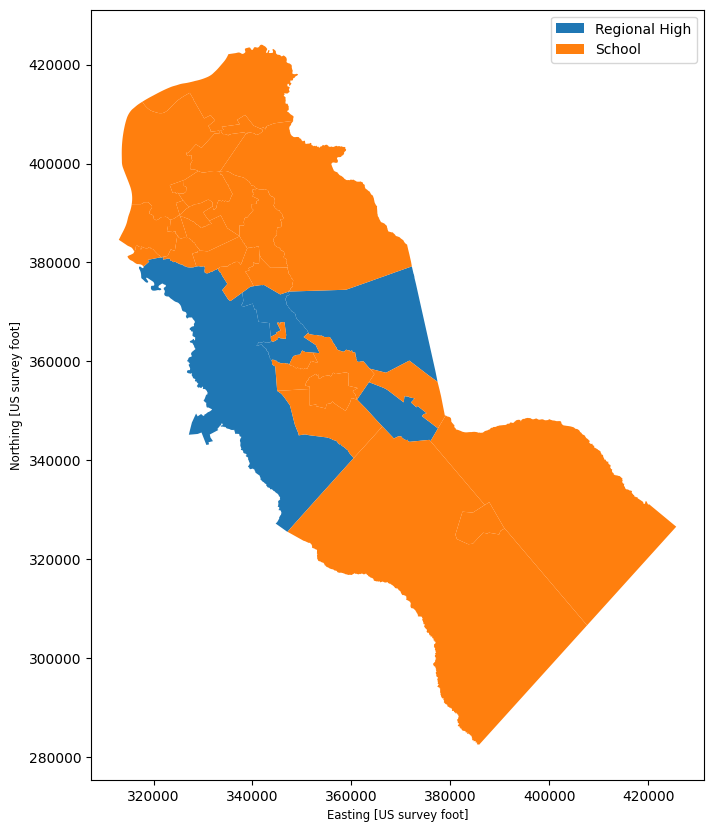

In [130]:
cchs.plot(column='type', legend=True, figsize=(10,10))